In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

df = pd.read_csv("Human Development Index - Full.csv")

In [2]:
original_df = df.copy()

In [3]:
for i, col in enumerate(df.columns):
    print(i, col)

0 ISO3
1 Country
2 Human Development Groups
3 UNDP Developing Regions
4 HDI Rank (2021)
5 Human Development Index (1990)
6 Human Development Index (1991)
7 Human Development Index (1992)
8 Human Development Index (1993)
9 Human Development Index (1994)
10 Human Development Index (1995)
11 Human Development Index (1996)
12 Human Development Index (1997)
13 Human Development Index (1998)
14 Human Development Index (1999)
15 Human Development Index (2000)
16 Human Development Index (2001)
17 Human Development Index (2002)
18 Human Development Index (2003)
19 Human Development Index (2004)
20 Human Development Index (2005)
21 Human Development Index (2006)
22 Human Development Index (2007)
23 Human Development Index (2008)
24 Human Development Index (2009)
25 Human Development Index (2010)
26 Human Development Index (2011)
27 Human Development Index (2012)
28 Human Development Index (2013)
29 Human Development Index (2014)
30 Human Development Index (2015)
31 Human Development Index (2016)

In [4]:
# -----------------------------------------
# CREATE A CLEAN LONG-FORM DATAFRAME
# -----------------------------------------

# 1. Columns that should remain unchanged
id_cols = [
    'ISO3',
    'Country',
    'Human Development Groups',
    'UNDP Developing Regions',
    'HDI Rank (2021)'
]

# 2. Every column after those 5 is a year-based variable
year_cols = df.columns[5:].tolist()

# 3. Melt the year-based columns
#    This preserves every value while putting the year-based
#    column names into one column.
long_df = df[id_cols + year_cols].melt(
    id_vars=id_cols,
    var_name='Indicator_Year',
    value_name='Value'
)

# 4. Separate the indicator name from the year
#    Example:
#    "Human Development Index (1990)"
#    becomes:
#    Indicator = "Human Development Index"
#    Year = 1990
long_df[['Indicator', 'Year']] = long_df['Indicator_Year'].str.extract(
    r'^(.*?) \((\d{4})\)$'
)

# 5. Convert Year from text to an integer
long_df['Year'] = long_df['Year'].astype(int)

# 6. We no longer need the original combined column
long_df = long_df.drop(columns='Indicator_Year')

# 7. Put the columns in the order we want
long_df = long_df[
    id_cols + ['Indicator', 'Year', 'Value']
]

In [5]:
long_df

,ISO3,Country,Human Development Groups,UNDP Developing Regions,HDI Rank (2021),Indicator,Year,Value
0,AFG,Afghanistan,Low,SA,180.0,Human Development Index,1990,0.273
1,AGO,Angola,Medium,SSA,148.0,Human Development Index,1990,NaN
2,ALB,Albania,High,ECA,67.0,Human Development Index,1990,0.647
3,AND,Andorra,Very High,NaN,40.0,Human Development Index,1990,NaN
4,ARE,United Arab Emirates,Very High,AS,26.0,Human Development Index,1990,0.728
...,...,...,...,...,...,...,...,...
170620,WSM,Samoa,High,EAP,111.0,Material footprint per capita (tonnes),2021,NaN
170621,YEM,Yemen,Low,AS,183.0,Material footprint per capita (tonnes),2021,2.890
170622,ZAF,South Africa,High,SSA,109.0,Material footprint per capita (tonnes),2021,7.550
170623,ZMB,Zambia,Medium,SSA,154.0,Material footprint per capita (tonnes),2021,2.380


In [6]:
long_df['Indicator'].value_counts()

Indicator
Human Development Index                                          6240
Life Expectancy at Birth                                         6240
Expected Years of Schooling                                      6240
Mean Years of Schooling                                          6240
Gross National Income Per Capita                                 6240
Gender Development Index                                         6240
HDI female                                                       6240
Life Expectancy at Birth, female                                 6240
Expected Years of Schooling, female                              6240
Mean Years of Schooling, female                                  6240
Gross National Income Per Capita, female                         6240
HDI male                                                         6240
Life Expectancy at Birth, male                                   6240
Expected Years of Schooling, male                                6240
Mean Years

In [7]:
clean_df = long_df.pivot_table(
    index=['ISO3', 'Country', 'Human Development Groups',
           'UNDP Developing Regions', 'HDI Rank (2021)', 'Year'],
    columns='Indicator',
    values='Value',
    aggfunc='first'
).reset_index()

clean_df.columns.name = None

In [8]:
clean_df

,ISO3,Country,Human Development Groups,UNDP Developing Regions,HDI Rank (2021),Year,"Adolescent Birth Rate (births per 1,000 women ages 15-19)",Carbon dioxide emissions per capita (production) (tonnes),Coefficient of human inequality,Difference from HDI rank,...,Life Expectancy at Birth,"Life Expectancy at Birth, female","Life Expectancy at Birth, male",Material footprint per capita (tonnes),"Maternal Mortality Ratio (deaths per 100,000 live births)",Mean Years of Schooling,"Mean Years of Schooling, female","Mean Years of Schooling, male",Overall loss (%),Planetary pressures-adjusted Human Development Index
0,AFG,Afghanistan,Low,SA,180.0,1990,142.960,0.209727,NaN,NaN,...,45.9672,48.3973,43.7088,2.33,1500.0,0.971125,0.342503,1.311020,NaN,0.270
1,AFG,Afghanistan,Low,SA,180.0,1991,147.525,0.182525,NaN,NaN,...,46.6631,49.1439,44.3528,2.28,1530.0,1.019356,0.371860,1.385486,NaN,0.276
2,AFG,Afghanistan,Low,SA,180.0,1992,147.521,0.095233,NaN,NaN,...,47.5955,50.3197,45.0697,2.35,1520.0,1.067586,0.401218,1.459952,NaN,0.284
3,AFG,Afghanistan,Low,SA,180.0,1993,147.896,0.084285,NaN,NaN,...,51.4664,52.7389,50.2164,2.10,1480.0,1.115817,0.430575,1.534418,NaN,0.294
4,AFG,Afghanistan,Low,SA,180.0,1994,155.669,0.075054,NaN,NaN,...,51.4945,53.5442,49.5307,1.83,1540.0,1.164047,0.459933,1.608884,NaN,0.289
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4731,ZWE,Zimbabwe,Medium,SSA,146.0,2017,98.265,0.673026,23.076460,NaN,...,60.7095,62.9561,58.2078,2.26,458.0,8.461690,8.061880,8.916270,23.232323,0.585
4732,ZWE,Zimbabwe,Medium,SSA,146.0,2018,98.507,0.821010,22.832887,NaN,...,61.4141,63.5940,58.9685,2.05,458.0,8.585395,8.178377,9.052420,23.089701,0.593
4733,ZWE,Zimbabwe,Medium,SSA,146.0,2019,97.354,0.747610,22.682058,NaN,...,61.2925,63.6614,58.6436,1.21,458.0,8.710909,8.296558,9.190648,22.961730,0.594
4734,ZWE,Zimbabwe,Medium,SSA,146.0,2020,96.180,0.708562,22.518490,NaN,...,61.1242,63.8616,58.1294,1.21,458.0,8.710909,8.296558,9.190648,22.833333,0.594


In [9]:
clean_df.shape

(4736, 40)

In [10]:
clean_df.duplicated(
    subset=['ISO3', 'Country', 'Year']
).sum()

np.int64(0)

In [16]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)

clean_df[clean_df['Country'] == 'Afghanistan'].head(35)

,ISO3,Country,Human Development Groups,UNDP Developing Regions,HDI Rank (2021),Year,"Adolescent Birth Rate (births per 1,000 women ages 15-19)",Carbon dioxide emissions per capita (production) (tonnes),Coefficient of human inequality,Difference from HDI rank,Difference from HDI value (%),Expected Years of Schooling,"Expected Years of Schooling, female","Expected Years of Schooling, male",GDI Group,GII Rank,Gender Development Index,Gender Inequality Index,Gross National Income Per Capita,"Gross National Income Per Capita, female","Gross National Income Per Capita, male",HDI female,HDI male,Human Development Index,Inequality in eduation,Inequality in income,Inequality in life expectancy,Inequality-adjusted Human Development Index,"Labour force participation rate, female (% ages 15 and older)","Labour force participation rate, male (% ages 15 and older)",Life Expectancy at Birth,"Life Expectancy at Birth, female","Life Expectancy at Birth, male",Material footprint per capita (tonnes),"Maternal Mortality Ratio (deaths per 100,000 live births)",Mean Years of Schooling,"Mean Years of Schooling, female","Mean Years of Schooling, male",Overall loss (%),Planetary pressures-adjusted Human Development Index
0,AFG,Afghanistan,Low,SA,180.0,1990,142.960,0.209727,NaN,NaN,1.098901,2.504050,1.970663,3.939093,NaN,NaN,0.595,NaN,2684.550019,668.055760,4700.298515,0.196280,0.329910,0.273,NaN,NaN,NaN,NaN,15.180,77.430,45.9672,48.3973,43.7088,2.33,1500.0,0.971125,0.342503,1.311020,NaN,0.270
1,AFG,Afghanistan,Low,SA,180.0,1991,147.525,0.182525,NaN,NaN,1.075269,2.806550,2.096679,4.171640,NaN,NaN,0.588,NaN,2276.289409,564.926374,3987.412921,0.196378,0.334046,0.279,NaN,NaN,NaN,NaN,15.214,77.176,46.6631,49.1439,44.3528,2.28,1530.0,1.019356,0.371860,1.385486,NaN,0.276
2,AFG,Afghanistan,Low,SA,180.0,1992,147.521,0.095233,NaN,NaN,1.045296,3.109050,2.230753,4.417915,NaN,NaN,0.586,NaN,2059.868084,508.750730,3611.099678,0.199362,0.340228,0.287,NaN,NaN,NaN,NaN,15.223,76.871,47.5955,50.3197,45.0697,2.35,1520.0,1.067586,0.401218,1.459952,NaN,0.284
3,AFG,Afghanistan,Low,SA,180.0,1993,147.896,0.084285,NaN,NaN,1.010101,3.411550,2.373401,4.678730,NaN,NaN,0.548,NaN,1525.533426,374.581093,2675.906967,0.195311,0.356374,0.297,NaN,NaN,NaN,NaN,15.197,76.580,51.4664,52.7389,50.2164,2.10,1480.0,1.115817,0.430575,1.534418,NaN,0.294
4,AFG,Afghanistan,Low,SA,180.0,1994,155.669,0.075054,NaN,NaN,1.027397,3.714050,2.525171,4.954942,NaN,NaN,0.524,NaN,1087.961890,266.207610,1908.508902,0.182092,0.347560,0.292,NaN,NaN,NaN,NaN,15.178,76.330,51.4945,53.5442,49.5307,1.83,1540.0,1.164047,0.459933,1.608884,NaN,0.289
5,AFG,Afghanistan,Low,SA,180.0,1995,156.770,0.067943,NaN,NaN,0.967742,4.016550,2.686646,5.247461,NaN,NaN,0.543,NaN,1339.087122,328.424135,2347.288210,0.199483,0.367555,0.310,NaN,NaN,NaN,NaN,15.221,76.102,52.5442,54.0874,51.0387,1.81,1490.0,1.212277,0.489290,1.683350,NaN,0.307
6,AFG,Afghanistan,Low,SA,180.0,1996,154.932,0.061787,NaN,NaN,0.940439,4.319050,2.858447,5.557248,NaN,NaN,0.544,NaN,1332.307210,324.316638,2336.562506,0.204408,0.376092,0.319,NaN,NaN,NaN,NaN,15.078,76.140,53.2433,54.8057,51.7216,1.62,1440.0,1.251383,0.518647,1.736839,NaN,0.316
7,AFG,Afghanistan,Low,SA,180.0,1997,156.444,0.056005,NaN,NaN,0.928793,4.621550,3.041233,5.885324,NaN,NaN,0.536,NaN,1230.261290,297.891472,2157.935831,0.204164,0.380761,0.323,NaN,NaN,NaN,NaN,14.954,76.262,53.6342,55.1513,52.1525,1.73,1470.0,1.290489,0.548005,1.790329,NaN,0.320
8,AFG,Afghanistan,Low,SA,180.0,1998,154.262,0.052144,NaN,NaN,0.925926,4.924050,3.235709,6.232769,NaN,NaN,0.534,NaN,1149.902390,277.725946,2016.629812,0.203052,0.380486,0.324,NaN,NaN,NaN,NaN,14.873,76.415,52.9431,54.8179,51.1337,2.08,1410.0,1.329594,0.577362,1.843818,NaN,0.321
9,AFG,Afghanistan,Low,SA,180.0,1999,154.416,0.040133,NaN,NaN,0.903614,5.226550,3.442620,6.600724,NaN,NaN,0.523,NaN,1071.800919,258.566333,1878.913793,0.205237,0.392279,0.332,NaN,NaN,NaN,NaN,14.827,76.549,54.8464,56.3004,53.4104,2.03,1470.0,1.368700,0.606720,1.897308,NaN,0.329


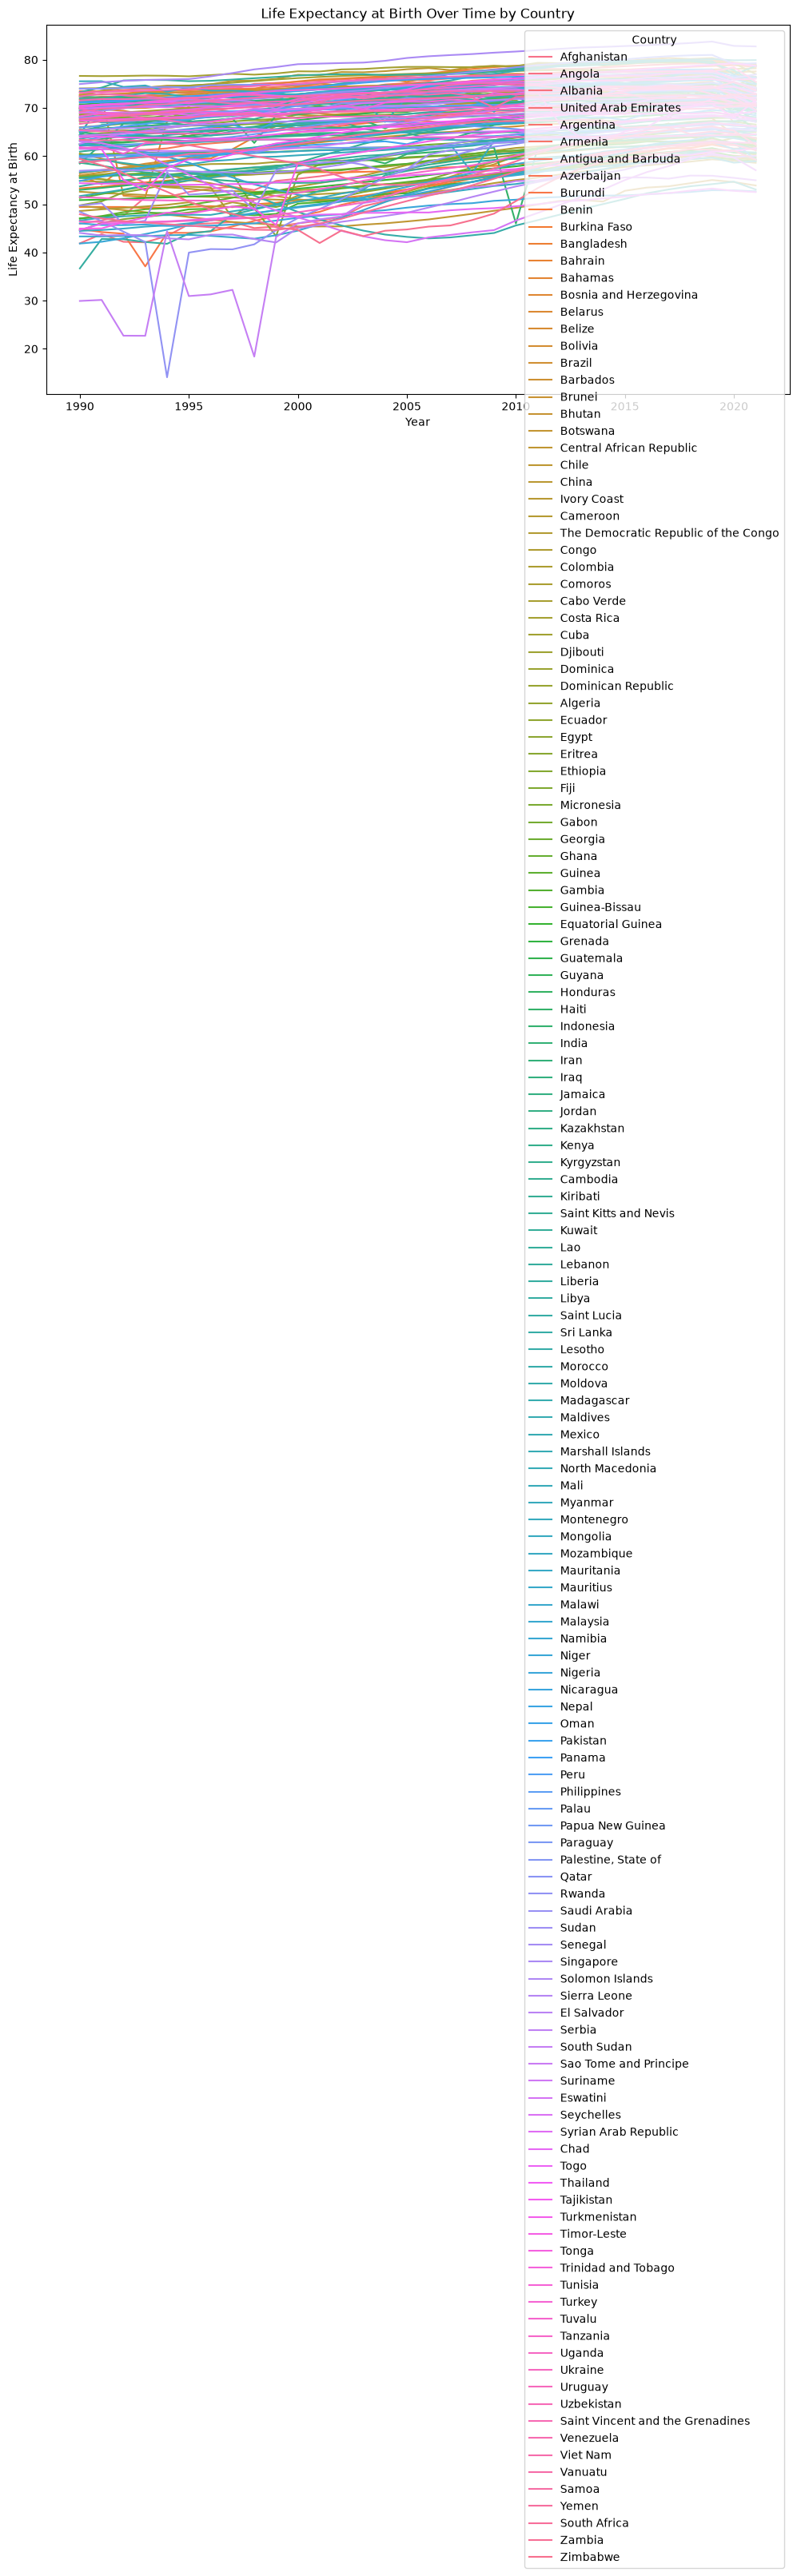

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=clean_df,
    x='Year',
    y='Life Expectancy at Birth',
    hue='Country'
)

plt.title('Life Expectancy at Birth Over Time by Country')
plt.xlabel('Year')
plt.ylabel('Life Expectancy at Birth')
plt.legend(title='Country')
plt.show()